[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch39_LabCh39_Fine_Tuning.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 39: Fine-Tuning: Standing on a Pretrained Model** (Part IX: Putting Big Models to Work).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=39](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=39)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch39 - Fine-Tuning
## Borrow a trained model, teach it a new task with 500 labels, and measure what it forgot

This lab goes with **Chapter 39** of *The Why Book of Deep Learning, Part 2*.

Training from nothing is the expensive way. In real work you start from a model that somebody else trained on
a large data set, and you nudge it towards your task. This lab plays both parts. First you are "somebody
else": you pretrain a small CNN on five CIFAR-10 classes. Then you are the person with a new task (the *other*
five classes), only **500 labelled images**, and a choice of how to use the borrowed model.

| | the old task (A) | the new task (B) |
|---|---|---|
| classes | airplane, automobile, bird, cat, deer | dog, frog, horse, ship, truck |
| labels available | 25,000 | **500** (100 per class) |
| who trains on it | "somebody else", in Step 5 | you, in Steps 6 to 11 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Split a model into a backbone and a head, and count each | Steps 3 and 4 |
| Run the four classic options on the same budget and read their curves | Steps 6 to 12 |
| Freeze, unfreeze and recompile correctly in Keras | Steps 7, 11 and 18 |
| Measure what a random head sends into a pretrained backbone | Step 10 |
| Measure catastrophic forgetting, and tell lost features from a disconnected head | Steps 13 to 15 |
| Climb one more rung of the ladder: unfreeze only the top block | Step 16 |
| Tell a repeatable recipe from a lucky run | Step 17 |
| Recognise three silent traps: no recompile, wrong preprocessing, BatchNorm in the wrong mode | Steps 18 to 20 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about three to five minutes on a laptop CPU. Step 5 (the pretraining) is the longest single
> cell. No GPU is needed. The only download is CIFAR-10 (`keras.datasets.cifar10`).

> **Honest scale:** this is a miniature. The "pretrained model" has under a hundred thousand parameters and saw
> 25,000 small images of five kinds of thing for about a minute. A real pretrained backbone has tens of
> millions of parameters and saw more than a million images of a thousand kinds, or billions of words. The
> *mechanics* you measure here (freezing, the head, the learning rate, forgetting) are the real ones. The
> *sizes of the gaps* are not: with a real backbone the advantage of starting pretrained is usually far larger
> than anything this lab can show.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 39
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - One data set, cut into an old task and a new task

CIFAR-10 has ten classes of 32 x 32 colour images. Classes 0 to 4 become **task A**, the task the borrowed
model was trained for. Classes 5 to 9 become **task B**, yours, relabelled 0 to 4.

For task B you get 500 labelled images to train on and 1,000 more to validate on. The 5,000 task-B test images
are opened once per model, at the end.

**Predict before you run:** pixels arrive as integers from 0 to 255. What range will they have after the
scaling below, and why will that one line matter again in Step 19?

In [2]:
NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.ravel(), y_test.ravel()

def prep(x):                                  # the preprocessing of this lab: one line, used everywhere
    return x.astype("float32") / 255.0

x_train, x_test = prep(x_train), prep(x_test)

# task A: classes 0-4, everything
xA, yA = x_train[y_train < 5], y_train[y_train < 5]
xA_test, yA_test = x_test[y_test < 5], y_test[y_test < 5]

# task B: classes 5-9 relabelled 0-4; 100 per class to train, 200 per class to validate
N_PER_CLASS, N_VAL_PER_CLASS = 100, 200
tr_idx, va_idx = [], []
for c in range(5, 10):
    idx = rng.permutation(np.where(y_train == c)[0])
    tr_idx += list(idx[:N_PER_CLASS])
    va_idx += list(idx[N_PER_CLASS:N_PER_CLASS + N_VAL_PER_CLASS])
tr_idx, va_idx = rng.permutation(tr_idx), np.array(va_idx)
xB, yB = x_train[tr_idx], y_train[tr_idx] - 5
xB_val, yB_val = x_train[va_idx], y_train[va_idx] - 5
xB_test, yB_test = x_test[y_test >= 5], y_test[y_test >= 5] - 5

print("task A  train", xA.shape, " test", xA_test.shape, " classes:", NAMES[:5])
print("task B  train", xB.shape, "   val", xB_val.shape, " test", xB_test.shape, " classes:", NAMES[5:])
print("task B labels per class:", np.bincount(yB), "| pixel range:", xB.min(), "to", xB.max())
assert len(set(tr_idx) & set(va_idx)) == 0          # no image is in both the training and the validation set

task A  train (25000, 32, 32, 3)  test (5000, 32, 32, 3)  classes: ['airplane', 'automobile', 'bird', 'cat', 'deer']
task B  train (500, 32, 32, 3)    val (1000, 32, 32, 3)  test (5000, 32, 32, 3)  classes: ['dog', 'frog', 'horse', 'ship', 'truck']
task B labels per class: [100 100 100 100 100] | pixel range: 0.0 to 1.0


---
## Step 3 - Count the model before building it

The model is a **backbone** (everything that turns an image into a vector of 128 features) and a **head**
(one `Dense` layer that turns the 128 features into 5 scores). Fine-tuning is all about treating those two
parts differently, so we count them separately.

The backbone has three stages: `Conv2D` (3 x 3, no bias) -> `BatchNormalization` -> ReLU, with 32, 64 and 128
filters, a 2 x 2 max-pool after the first two and a global average pool at the end.

- A 3 x 3 convolution without bias has `3 * 3 * channels_in * filters` weights (Chapter 14).
- BatchNorm keeps four numbers per channel: two are trained (scale and shift), two are running statistics
  (mean and variance) that are *never* trained by gradient (Chapter 10).

**Predict before you run:** which of the three convolutions holds the most weights? How many numbers does the
head have?

In [3]:
def count_backbone(filters=(32, 64, 128), c_in=3):
    trainable = frozen_stats = 0
    for f in filters:
        trainable += 3 * 3 * c_in * f        # conv kernel, no bias
        trainable += 2 * f                   # BatchNorm scale and shift
        frozen_stats += 2 * f                # BatchNorm moving mean and variance
        c_in = f
    return trainable, frozen_stats

BB_TRAINABLE, BB_STATS = count_backbone()
HEAD = 128 * 5 + 5
print("conv kernels      :", [3 * 3 * a * b for a, b in [(3, 32), (32, 64), (64, 128)]])
KERNELS = 864 + 18_432 + 73_728
print("three kernels     :", f"{KERNELS:,}")
print("backbone trainable:", f"{BB_TRAINABLE:,}", "(kernels + BatchNorm scale and shift)")
print("backbone BN stats :", f"{BB_STATS:,}", "(never trained by gradient)")
print("backbone total    :", f"{BB_TRAINABLE + BB_STATS:,}")
print("head              :", f"{HEAD:,}")
print("whole model       :", f"{BB_TRAINABLE + BB_STATS + HEAD:,}")
print(f"the head is {100 * HEAD / (BB_TRAINABLE + BB_STATS + HEAD):.2f}% of the model")

conv kernels      : [864, 18432, 73728]
three kernels     : 93,024
backbone trainable: 93,472 (kernels + BatchNorm scale and shift)
backbone BN stats : 448 (never trained by gradient)
backbone total    : 93,920
head              : 645
whole model       : 94,565
the head is 0.68% of the model


---
## Step 4 - Build the backbone and the model

Two small functions do all the building in this lab.

`make_backbone()` returns the backbone as its own Keras model, so that it can be frozen, copied and measured
as one object.

`build(base, train_base, bn)` puts a new head on a backbone. `train_base` says whether the backbone's weights
may change. `bn` says what its BatchNorm layers do while the backbone is being trained:

- `bn="frozen"` (the default): every BatchNorm layer is set to `trainable = False`. In Keras a frozen
  BatchNorm layer runs in *inference mode*: it normalises with the statistics it stored during pretraining and
  does not update them. The backbone is also called with `training=False`, as the Keras guides recommend.
- `bn="call_only"` relies on `training=False` in the call alone, and `bn="training"` lets BatchNorm behave as
  it does when training from nothing. They are for Step 20 and for the from-scratch model, which has no
  stored statistics worth keeping.

**Predict before you run:** the summary will show the backbone as a single line. What output shape and how many
parameters will that line show?

In [4]:
LOSS = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

def make_backbone():
    inputs = layers.Input(shape=(32, 32, 3))
    x = inputs
    for k, f in enumerate([32, 64, 128], start=1):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"conv{k}")(x)
        x = layers.BatchNormalization(momentum=0.9, name=f"bn{k}")(x)
        x = layers.ReLU(name=f"relu{k}")(x)
        if k < 3:
            x = layers.MaxPooling2D(name=f"pool{k}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    return keras.Model(inputs, x, name="backbone")

def set_trainable(base, train, bn="frozen"):
    base.trainable = train                                   # sets every layer inside the backbone
    if train and bn == "frozen":
        for layer in base.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False                      # frozen BatchNorm = inference mode, stored statistics

def build(base, train_base, bn="frozen"):
    set_trainable(base, train_base, bn)
    inputs = layers.Input(shape=(32, 32, 3))
    feats = base(inputs) if bn == "training" else base(inputs, training=False)
    outputs = layers.Dense(5, name="head")(feats)            # logits for 5 classes
    return keras.Model(inputs, outputs)

def n_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

base_A = make_backbone()
model_A = build(base_A, train_base=True, bn="training")      # trained from nothing, so BatchNorm learns its statistics
model_A.summary()
assert base_A.count_params() == BB_TRAINABLE + BB_STATS == 93_920
assert model_A.count_params() == 94_565 and n_trainable(model_A) == BB_TRAINABLE + HEAD == 94_117
print("hand count and Keras agree:", f"{model_A.count_params():,} parameters, {n_trainable(model_A):,} trainable")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ backbone (Functional)           │ (None, 128)            │        93,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,565 (369.39 KB)

 Trainable params: 94,117 (367.64 KB)

 Non-trainable params: 448 (1.75 KB)

hand count and Keras agree: 94,565 parameters, 94,117 trainable


### Why we see this

The backbone line shows `(None, 128)` and 93,920 parameters: an image goes in, 128 numbers come out. The head
is 645 numbers, well under one percent of the model. Hold on to that proportion. In feature extraction (Step 7)
those 645 numbers are *all* you train.

---
## Step 5 - Be "somebody else": pretrain on task A

Six passes over the 25,000 task-A images, with the learning rate falling smoothly to zero so that the model
ends in a settled place. This is the long cell of the lab (about a minute). In real work you never run this
step: somebody else spent the days and the money, and you download the result.

**Predict before you run:** five classes, so a blind guess scores 20%. What test accuracy do you expect after
six epochs from a model this small?

In [5]:
def compile_(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=LOSS, metrics=["accuracy"])

t0 = time.time()
PRE_EPOCHS = 6
steps = PRE_EPOCHS * int(np.ceil(len(xA) / 64))
compile_(model_A, keras.optimizers.schedules.CosineDecay(1e-3, steps))     # 1e-3 falling smoothly to 0 (Chapter 8)
hist_A = model_A.fit(xA, yA, batch_size=64, epochs=PRE_EPOCHS, verbose=2)
ACC_A = model_A.evaluate(xA_test, yA_test, batch_size=500, verbose=0)[1]
print(f"\npretraining took {time.time() - t0:.0f}s | task A test accuracy {100 * ACC_A:.1f}%")

# what you would download: the backbone's weights, and (rarely useful) the old head
PRETRAINED = [w.copy() for w in base_A.get_weights()]
OLD_W, OLD_B = [w.copy() for w in model_A.get_layer("head").get_weights()]

def pretrained_backbone():
    """A fresh copy of the pretrained backbone, so every experiment starts from the same weights."""
    b = make_backbone()
    b.set_weights(PRETRAINED)
    return b

Epoch 1/6


391/391 - 29s - 73ms/step - accuracy: 0.6262 - loss: 0.9489


Epoch 2/6


391/391 - 22s - 57ms/step - accuracy: 0.7056 - loss: 0.7668


Epoch 3/6


391/391 - 12s - 31ms/step - accuracy: 0.7411 - loss: 0.6829


... (3 outputs left out)

391/391 - 12s - 31ms/step - accuracy: 0.7887 - loss: 0.5740


Epoch 6/6


391/391 - 12s - 31ms/step - accuracy: 0.7999 - loss: 0.5485



pretraining took 101s | task A test accuracy 78.7%


---
## Step 6 - Baseline: train from nothing on the 500 new labels

Every experiment from here on uses the same budget: **24 epochs over the 500 task-B images, batch size 32**
(16 steps per epoch, 384 steps in all), Adam, and the validation accuracy recorded after every epoch.

First the expensive way: the same architecture with random weights, trained on the 500 images only.

**Predict before you run:** training accuracy after 24 epochs? Validation accuracy? How far apart?

In [6]:
EPOCHS, BATCH = 24, 32
CURVES, TRAIN_ACC, TEST_ACC = {}, {}, {}

def fit(model, lr, epochs, first_epoch=0, validate=True):
    """Compile at this learning rate and train on the 500 task-B images. Returns per-epoch validation and training accuracy."""
    compile_(model, lr)
    h = model.fit(xB, yB, batch_size=BATCH, epochs=first_epoch + epochs, initial_epoch=first_epoch,
                  validation_data=(xB_val, yB_val) if validate else None, verbose=0)
    return h.history.get("val_accuracy", []), h.history.get("accuracy", [])

def finish(name, model, val, train):
    CURVES[name], TRAIN_ACC[name] = val, train
    TEST_ACC[name] = model.evaluate(xB_test, yB_test, batch_size=500, verbose=0)[1]
    print(f"{name:<28} trainable {n_trainable(model):>7,} | train {100 * train[-1]:5.1f}% | "
          f"val best {100 * max(val):5.1f}% (epoch {int(np.argmax(val)) + 1:>2}) last {100 * val[-1]:5.1f}% | "
          f"test {100 * TEST_ACC[name]:5.1f}%")

base_scratch = make_backbone()                                   # random weights
m_scratch = build(base_scratch, train_base=True, bn="training")
val, train = fit(m_scratch, 1e-3, EPOCHS)
finish("1 from scratch", m_scratch, val, train)

1 from scratch               trainable  94,117 | train  96.4% | val best  67.3% (epoch 22) last  58.6% | test  59.7%


### Why we see this

The training accuracy climbs high while the validation accuracy stays far below it: 94,117 free numbers and
500 pictures. The model has more than enough room to memorise the pictures, and nothing forces it to learn
features that also work on pictures it has not seen. The validation accuracy also jumps about from epoch to
epoch (it is plotted in Step 12): the best epoch and the last epoch are several points apart.

---
## Step 7 - Feature extraction: freeze the backbone, train a new head

Now use the borrowed model in the cheapest way that involves any training. Freeze the whole backbone and train
only a new head. The backbone becomes a fixed function from an image to 128 numbers, and you fit a small
classifier on those numbers.

A head on frozen features is a logistic regression: one layer, a well-behaved loss. It tolerates a learning
rate ten times larger than a deep network does, so the head is trained at `HEAD_LR = 1e-2` whenever the
backbone is frozen. (Trial 4 puts it back to 1e-3: the head is then still climbing when the budget runs out.)

**Predict before you run:** how many trainable parameters will Keras report? Will this beat training from
scratch? Remember that the backbone has never seen a dog, a frog, a horse, a ship or a truck.

In [7]:
HEAD_LR = 1e-2
base_frozen = pretrained_backbone()
m_frozen = build(base_frozen, train_base=False)
assert n_trainable(m_frozen) == HEAD == 645
val, train = fit(m_frozen, HEAD_LR, EPOCHS)
finish("2 frozen backbone + head", m_frozen, val, train)

def backbone_moved(base):
    return max(np.abs(a - b).max() for a, b in zip(base.get_weights(), PRETRAINED))

print("largest change in any backbone number:", backbone_moved(base_frozen))

2 frozen backbone + head     trainable     645 | train  76.2% | val best  72.8% (epoch 24) last  72.8% | test  73.2%
largest change in any backbone number: 0.0


### Why we see this

645 trainable numbers cannot memorise 500 images, so the training and validation accuracy stay close together.
The features were learnt on aeroplanes, cars, birds, cats and deer, yet they are useful for dogs and trucks:
edges, colour blobs, fur-like and metal-like textures are not about any one class. The largest change in the
backbone is exactly 0.0. Whatever this model could do on task A, it can still do.

---
## Step 8 - Full fine-tuning the careless way

Unfreeze the kernels, put a fresh random head on top, and train the lot at the learning rate you would use
from scratch, 1e-3. This is what you get if you load a pretrained model and call `fit` without thinking.
(BatchNorm is kept frozen here, as in the careful run, so that the two differ only in the head and the rate.)

**Predict before you run:** better or worse than the frozen backbone on task B? What do you expect it to have
done to the pretrained weights? (Step 13 measures that.)

In [8]:
keras.utils.set_random_seed(SEED)
base_fast = pretrained_backbone()
m_fast = build(base_fast, train_base=True)
assert n_trainable(m_fast) == KERNELS + HEAD == 93_669        # three kernels and the head; BatchNorm stays frozen
val, train = fit(m_fast, 1e-3, EPOCHS)
finish("3 full fine-tune, lr 1e-3", m_fast, val, train)

3 full fine-tune, lr 1e-3    trainable  93,669 | train  75.6% | val best  66.7% (epoch 23) last  63.1% | test  65.9%


---
## Step 9 - The careful way, phase 1: warm up the head

The careful recipe has two phases inside the same 24-epoch budget. Phase 1 (8 epochs): backbone frozen, train
the new head at `HEAD_LR`. This is Step 7 again, stopped early.

**Predict before you run:** look at the Step 7 curve in your head. After 8 epochs, is the head most of the way
to its final accuracy, or far from it?

In [9]:
WARM_EPOCHS = 8
keras.utils.set_random_seed(SEED)
base_gentle = pretrained_backbone()
m_gentle = build(base_gentle, train_base=False)
val_1, train_1 = fit(m_gentle, HEAD_LR, WARM_EPOCHS)
WARM_HEAD = [w.copy() for w in m_gentle.get_layer("head").get_weights()]
if WARM_EPOCHS > 0:
    print(f"after {WARM_EPOCHS} epochs of head-only training: train {100 * train_1[-1]:.1f}% | val {100 * val_1[-1]:.1f}%")

after 8 epochs of head-only training: train 73.0% | val 70.3%


---
## Step 10 - Why the head goes first: measure what reaches the backbone

Before unfreezing, measure the thing the recipe is designed to avoid. Take the pretrained backbone and compute
the gradient that one pass over the 500 images would send into its kernels, three times:

- with a **fresh random head** on top,
- with a **different random head**,
- with the **warmed-up head** from Step 9.

We print the loss, the size (norm) of the gradient arriving at the backbone, and the cosine between gradients:
+1 means two gradients push the backbone the same way, 0 means unrelated directions, -1 means opposite ways.

**Predict before you run:** which head sends the largest gradient into the backbone? Does a random head ask the
backbone to move in the direction that the trained head asks for?

In [10]:
def backbone_gradient(head_weights=None, seed=0):
    """Loss on the 500 images, and the gradient of that loss with respect to the pretrained kernels (flattened)."""
    keras.utils.set_random_seed(seed)
    base = pretrained_backbone()
    model = build(base, train_base=True)
    if head_weights is not None:
        model.get_layer("head").set_weights(head_weights)
    with tf.GradientTape() as tape:
        loss = LOSS(yB, model(xB, training=False))
    grads = tape.gradient(loss, base.trainable_weights)
    return float(loss), np.concatenate([g.numpy().ravel() for g in grads])

def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

RANDOM = {seed: backbone_gradient(seed=seed) for seed in (1, 2, 3)}
loss_w, g_w = backbone_gradient(WARM_HEAD)
keras.utils.set_random_seed(SEED)

print(f"blind guess over 5 classes : loss {np.log(5):.3f}")
for seed, (loss, g) in RANDOM.items():
    print(f"random head {seed}              : loss {loss:.3f} | gradient into backbone {np.linalg.norm(g):6.2f} "
          f"({np.linalg.norm(g) / np.linalg.norm(g_w):.1f} times the warmed head's) | cosine with warmed head {cosine(g, g_w):+.2f}")
print(f"warmed-up head             : loss {loss_w:.3f} | gradient into backbone {np.linalg.norm(g_w):6.2f}")
print("cosine between random heads: " + ", ".join(f"{a} and {b}: {cosine(RANDOM[a][1], RANDOM[b][1]):+.2f}" for a, b in [(1, 2), (1, 3), (2, 3)]))

blind guess over 5 classes : loss 1.609
random head 1              : loss 1.868 | gradient into backbone  11.31 (1.7 times the warmed head's) | cosine with warmed head -0.57
random head 2              : loss 1.994 | gradient into backbone  21.37 (3.2 times the warmed head's) | cosine with warmed head -0.80
random head 3              : loss 1.718 | gradient into backbone   7.84 (1.2 times the warmed head's) | cosine with warmed head -0.18
warmed-up head             : loss 0.700 | gradient into backbone   6.65
cosine between random heads: 1 and 2: +0.62, 1 and 3: -0.25, 2 and 3: +0.13


### Why we see this

The gradient that reaches the backbone has passed *through the head* on its way down (backpropagation,
Chapter 7). A random head knows nothing about the task. Its loss is above that of a blind guess, so the error
signal it sends down is larger than the warmed head's (a little larger for one head, about three times for
another), and its direction is set by the head's random weights, not by dogs and trucks. Look at the cosines
with the warmed head: every one is negative. A random head does not ask for a noisy version of the right
change. It asks for something else, and the three random heads do not even agree with each other. The first
steps of a careless fine-tune therefore push good weights hard in a direction the task never asked for. Warm
the head up first and the message the backbone receives is smaller and is about the task.

---
## Step 11 - The careful way, phase 2: unfreeze, recompile, small learning rate

Phase 2 (the remaining 16 epochs): unfreeze the kernels, **recompile**, and continue at 1e-4, ten times below
the from-scratch rate and a hundred times below the head's rate.

**Predict before you run:** will phase 2 improve on the frozen run of Step 7? Will it end above or below the
careless run of Step 8?

In [11]:
set_trainable(base_gentle, True)                   # unfreeze the kernels (BatchNorm layers stay frozen) ...
val_2, train_2 = fit(m_gentle, 1e-4, EPOCHS - WARM_EPOCHS, first_epoch=WARM_EPOCHS)    # ... and fit() recompiles
assert n_trainable(m_gentle) == KERNELS + HEAD
finish("4 head first, then lr 1e-4", m_gentle, val_1 + val_2, train_1 + train_2)

4 head first, then lr 1e-4   trainable  93,669 | train  80.0% | val best  72.3% (epoch 23) last  72.2% | test  73.0%


---
## Step 12 - The four runs side by side

**Predict before you run:** rank the four runs by test accuracy before you look.

run                            train  val best  val last    test  wobble
1 from scratch                 96.4%     67.3%     58.6%   59.7%    8.2
2 frozen backbone + head       76.2%     72.8%     72.8%   73.2%    0.1
3 full fine-tune, lr 1e-3      75.6%     66.7%     63.1%   65.9%    0.9
4 head first, then lr 1e-4     80.0%     72.3%     72.2%   73.0%    0.2

validation accuracy (%) at epochs 1, 2, 4, 8, 12, 16, 20, 24:
1 from scratch                23.9  34.3  61.1  51.6  63.9  64.4  52.2  58.6
2 frozen backbone + head      57.6  62.9  68.8  71.5  71.6  72.0  72.2  72.8
3 full fine-tune, lr 1e-3     37.0  44.9  48.9  62.9  64.7  65.9  65.7  63.1
4 head first, then lr 1e-4    51.1  60.4  67.6  70.3  70.8  71.7  71.8  72.2


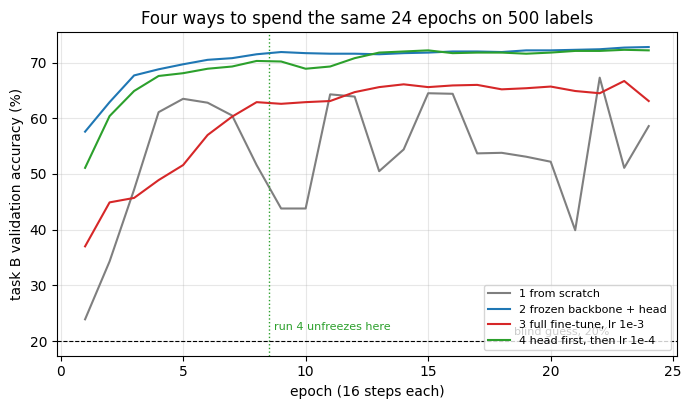

In [12]:
def wobble(v):                       # mean absolute change in validation accuracy between epochs, last 12 epochs
    return 100 * np.mean(np.abs(np.diff(v[-12:])))

print(f"{'run':<28} {'train':>7} {'val best':>9} {'val last':>9} {'test':>7} {'wobble':>7}")
for name in CURVES:
    v = CURVES[name]
    print(f"{name:<28} {100 * TRAIN_ACC[name][-1]:6.1f}% {100 * max(v):8.1f}% {100 * v[-1]:8.1f}% {100 * TEST_ACC[name]:6.1f}% {wobble(v):6.1f}")
SHOW = [e for e in [1, 2, 4, 8, 12, 16, 20, 24] if e <= EPOCHS]
print("\nvalidation accuracy (%) at epochs " + ", ".join(map(str, SHOW)) + ":")
for name in CURVES:
    print(f"{name:<28}", " ".join(f"{100 * CURVES[name][e - 1]:5.1f}" for e in SHOW))

COLOURS = {"1 from scratch": "tab:gray", "2 frozen backbone + head": "tab:blue",
           "3 full fine-tune, lr 1e-3": "tab:red", "4 head first, then lr 1e-4": "tab:green"}
plt.figure(figsize=(8, 4.2))
for name, c in COLOURS.items():
    plt.plot(range(1, EPOCHS + 1), 100 * np.array(CURVES[name]), color=c, label=name)
plt.axvline(WARM_EPOCHS + 0.5, color="tab:green", ls=":", lw=1)
plt.text(WARM_EPOCHS + 0.7, 22, "run 4 unfreezes here", color="tab:green", fontsize=8)
plt.axhline(20, color="k", ls="--", lw=0.8); plt.text(18.5, 21, "blind guess, 20%", fontsize=8)
plt.xlabel("epoch (16 steps each)"); plt.ylabel("task B validation accuracy (%)")
plt.title("Four ways to spend the same 24 epochs on 500 labels"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()

### Why we see this

Read the table and the plot together, and compare them with your ranking.

- **From scratch** has the highest training accuracy and the lowest test accuracy: it memorises.
- **Every run that starts from the pretrained backbone beats it** by a wide margin, although the backbone never
  saw one image of the new classes. That is the whole case for starting from a pretrained model.
- **The frozen backbone and the careful fine-tune finish within a point of each other.** This is the result that
  does not fit the slogan "fine-tuning beats feature extraction", and it is the right result for this corner of
  the map: 500 labels and a new task that is a close cousin of the old one. The borrowed features already fit,
  and 500 pictures are not enough evidence to improve 93,024 kernel weights by much.
- **The careless run** ends well below both in this run. Hold that thought: how it ends depends a good deal on
  the luck of its random head, and Step 17 runs it again.

If you stopped here you might conclude that the three pretrained runs are roughly equivalent. They are not.
The difference is on the task you are no longer looking at.

---
## Step 13 - Forgetting: go back and test the old task

A fine-tuned model is usually shipped after a look at the new task only. Now do what is rarely done: put the
**old head** (saved in Step 5) back on each backbone and measure task A again on its 5,000 test images.

**Predict before you run:** the pretrained model scored the task-A accuracy printed in Step 5. What will each
of the three backbones score now: frozen, careless, careful?

In [13]:
def old_task_accuracy(base):
    feats = base.predict(xA_test, batch_size=500, verbose=0)          # inference mode
    return float(((feats @ OLD_W + OLD_B).argmax(axis=1) == yA_test).mean())

BASES = {"pretrained, untouched": pretrained_backbone(), "2 frozen backbone + head": base_frozen,
         "3 full fine-tune, lr 1e-3": base_fast, "4 head first, then lr 1e-4": base_gentle}
OLD_ACC = {name: old_task_accuracy(b) for name, b in BASES.items()}
print(f"{'backbone':<28} {'old task A':>11} {'lost':>7} {'new task B':>11}")
for name, acc in OLD_ACC.items():
    new = f"{100 * TEST_ACC[name]:10.1f}%" if name in TEST_ACC else "         -"
    print(f"{name:<28} {100 * acc:10.1f}% {100 * (OLD_ACC['pretrained, untouched'] - acc):6.1f} {new}")

backbone                      old task A    lost  new task B
pretrained, untouched              78.7%    0.0          -
2 frozen backbone + head           78.7%    0.0       73.2%
3 full fine-tune, lr 1e-3          16.0%   62.7       65.9%
4 head first, then lr 1e-4         75.0%    3.7       73.0%


### Why we see this

Nothing in the fine-tuning loss mentions task A. Gradient descent moves every unfrozen weight wherever task B
improves, and whatever task A needed from those weights is not protected. This is **catastrophic forgetting**,
and nobody sees it unless they go back and test.

The frozen backbone forgot nothing, because nothing moved. The careful run lost a few points. The careless run
lost most of what it knew, for no gain on the new task. If your shipped model must still do its old job, this
table matters more than the one in Step 12.

---
## Step 14 - How far did the weights travel?

Forgetting is the weights moving away from where pretraining left them. Measure the distance, layer by layer:
the size of the change divided by the size of the pretrained kernel.

**Predict before you run:** which run moved its weights further, and by roughly what factor? Within a run,
which convolution moved most in relative terms: the first (edges and colours) or the last (the most
task-specific features)?

In [14]:
def travel(base):
    out = []
    for k in (1, 2, 3):
        w0 = PRETRAINED[[w.path for w in base.weights].index(f"conv{k}/kernel")]
        w1 = base.get_layer(f"conv{k}").get_weights()[0]
        out.append(np.linalg.norm(w1 - w0) / np.linalg.norm(w0))
    return out

print(f"{'relative change of kernel':<28} {'conv1':>7} {'conv2':>7} {'conv3':>7}")
TRAVEL = {}
for name in list(BASES)[1:]:
    TRAVEL[name] = travel(BASES[name])
    print(f"{name:<28} " + " ".join(f"{100 * t:6.1f}%" for t in TRAVEL[name]))
ratio = [a / b for a, b in zip(TRAVEL["3 full fine-tune, lr 1e-3"], TRAVEL["4 head first, then lr 1e-4"])]
print(f"{'careless / careful':<28} " + " ".join(f"{r:6.1f}x" for r in ratio))

relative change of kernel      conv1   conv2   conv3
2 frozen backbone + head        0.0%    0.0%    0.0%
3 full fine-tune, lr 1e-3       9.7%   23.7%   38.4%
4 head first, then lr 1e-4      1.3%    3.2%    4.2%
careless / careful              7.5x    7.5x    9.1x


### Why we see this

The careless run travelled several times further in every layer. In both runs the last convolution moved the
most and the first the least, with the same learning rate on every layer. Nobody told the optimiser to spare
the early layers. Edge and colour detectors are already what the new task needs, so the loss has little to say
to them, while the most task-specific features have the most to change. That pattern is the reason people
freeze from the bottom up and, when they use different learning rates per layer, give the smallest to the
earliest layers.

---
## Step 15 - Destroyed, or only disconnected?

The old head was fitted to the old features. When the features move, the old head no longer matches them, even
if the information about aeroplanes and cats is still in there. To separate the two effects, freeze each
backbone, compute its 128 features for 5,000 task-A training images, and fit a **fresh** head for task A on
those features (a *linear probe*). If the probe scores well, the knowledge was still in the features and only
the connection was lost.

**Predict before you run:** will a re-fitted head recover all of the lost accuracy, some of it, or none?

In [15]:
def probe_old_task(base, n=5000, epochs=20):
    keras.utils.set_random_seed(SEED)
    f_train = base.predict(xA[:n], batch_size=500, verbose=0)
    f_test = base.predict(xA_test, batch_size=500, verbose=0)
    probe = keras.Sequential([layers.Input(shape=(128,)), layers.Dense(5)])
    probe.compile(optimizer=keras.optimizers.Adam(1e-2), loss=LOSS, metrics=["accuracy"])
    probe.fit(f_train, yA[:n], batch_size=64, epochs=epochs, verbose=0)
    return probe.evaluate(f_test, yA_test, batch_size=500, verbose=0)[1]

PROBE = {name: probe_old_task(b) for name, b in BASES.items() if not name.startswith("2")}
print(f"{'backbone':<28} {'old head':>9} {'re-fitted head':>15}")
for name, acc in PROBE.items():
    print(f"{name:<28} {100 * OLD_ACC[name]:8.1f}% {100 * acc:14.1f}%")

backbone                      old head  re-fitted head
pretrained, untouched            78.7%           78.8%
3 full fine-tune, lr 1e-3        16.0%           66.5%
4 head first, then lr 1e-4       75.0%           78.4%


### Why we see this

Two different things hide under the word "forgetting". Part of the drop in Step 13 is a head that no longer
fits features that have shifted: a new head, fitted on old-task data, wins much of it back. The rest is real
loss: features that task A relied on were overwritten because task B had no use for them, and no head can read
what is no longer there. The first kind is cheap to repair *if you still have old-task data*. Often you do
not: it belonged to whoever pretrained the model.

---
## Step 16 - One more rung: unfreeze only the top block

Between "freeze everything" and "train everything" sits **partial fine-tuning**: keep the early layers frozen
and train only the last convolution with the head. This run starts from the warmed head of Step 9, so it is
directly comparable with phase 2 of run 4: 16 epochs at 1e-4.

**Predict before you run:** how many trainable parameters? Where will its task-B accuracy and its forgetting
fall between run 2 and run 4?

In [16]:
keras.utils.set_random_seed(SEED)
base_top = pretrained_backbone()
m_top = build(base_top, train_base=True)
for layer in base_top.layers:
    layer.trainable = layer.name == "conv3"                   # everything else stays frozen
m_top.get_layer("head").set_weights(WARM_HEAD)
assert n_trainable(m_top) == 3 * 3 * 64 * 128 + HEAD == 74_373
val_t, train_t = fit(m_top, 1e-4, EPOCHS - WARM_EPOCHS, first_epoch=WARM_EPOCHS)
finish("5 top block only, lr 1e-4", m_top, val_1 + val_t, train_1 + train_t)
OLD_ACC["5 top block only, lr 1e-4"] = old_task_accuracy(base_top)
print(f"old task A with the old head: {100 * OLD_ACC['5 top block only, lr 1e-4']:.1f}%   "
      f"(run 2: {100 * OLD_ACC['2 frozen backbone + head']:.1f}%, run 4: {100 * OLD_ACC['4 head first, then lr 1e-4']:.1f}%)")

5 top block only, lr 1e-4    trainable  74,373 | train  78.4% | val best  72.9% (epoch 22) last  72.8% | test  73.1%


old task A with the old head: 76.0%   (run 2: 78.7%, run 4: 75.0%)


---
## Step 17 - How much of that was luck?

One run of each recipe is an anecdote. The careless run starts from a random head, and Step 10 showed that
different random heads send different gradients into the backbone. Repeat runs 3 and 4 with two more seeds and
look at the spread.

**Predict before you run:** which recipe gives nearly the same result every time, and which is a lottery? On
which task will the spread be largest?

In [17]:
def again(seed):
    keras.utils.set_random_seed(seed)
    b3 = pretrained_backbone(); m3 = build(b3, train_base=True)
    fit(m3, 1e-3, EPOCHS, validate=False)
    keras.utils.set_random_seed(seed)
    b4 = pretrained_backbone(); m4 = build(b4, train_base=False)
    fit(m4, HEAD_LR, WARM_EPOCHS, validate=False)
    set_trainable(b4, True)
    fit(m4, 1e-4, EPOCHS - WARM_EPOCHS, first_epoch=WARM_EPOCHS, validate=False)
    return [m.evaluate(xB_test, yB_test, batch_size=500, verbose=0)[1] for m in (m3, m4)] + [old_task_accuracy(b) for b in (b3, b4)]

LUCK = {SEED: [TEST_ACC["3 full fine-tune, lr 1e-3"], TEST_ACC["4 head first, then lr 1e-4"],
               OLD_ACC["3 full fine-tune, lr 1e-3"], OLD_ACC["4 head first, then lr 1e-4"]]}
for seed in (1, 2):
    LUCK[seed] = again(seed)
keras.utils.set_random_seed(SEED)

print(f"{'seed':>6} | {'careless: new B':>16} {'old A':>7} | {'careful: new B':>15} {'old A':>7}")
for seed, (b3, b4, a3, a4) in LUCK.items():
    print(f"{seed:>6} | {100 * b3:15.1f}% {100 * a3:6.1f}% | {100 * b4:14.1f}% {100 * a4:6.1f}%")
L = 100 * np.array(list(LUCK.values()))
print(f"{'spread':>6} | {L[:, 0].max() - L[:, 0].min():15.1f}  {L[:, 2].max() - L[:, 2].min():6.1f}  | {L[:, 1].max() - L[:, 1].min():14.1f}  {L[:, 3].max() - L[:, 3].min():6.1f}    (highest minus lowest, in points)")

  seed |  careless: new B   old A |  careful: new B   old A
    39 |            65.9%   16.0% |           73.0%   75.0%
     1 |            71.6%   52.1% |           74.3%   74.1%
     2 |            74.6%   51.9% |           74.0%   71.9%
spread |             8.7    36.1  |            1.4     3.1    (highest minus lowest, in points)


### Why we see this

The careful recipe is repeatable: the head has settled before the backbone is allowed to move, and the small
rate keeps the backbone near where it started, so the seed has little to decide. The careless recipe lets a
random head steer the backbone at full speed in its first steps, and where the backbone ends up, on both tasks,
depends on which random head it was given. With a lucky head it can match or even edge past the careful run on
the new task. It never keeps the old one: every careless run lost far more of task A than any careful run.
Three seeds are still a small sample. They are enough to stop you quoting a single run of either recipe as
"the" result, and enough to show which recipe you can rely on.

---
## Step 18 - Trap 1: unfreezing without recompiling

Keras fixes the list of weights to train when the model is compiled and first trained. Change `trainable`
afterwards and nothing warns you. This cell trains a frozen model for one epoch, unfreezes the backbone,
trains again **without** recompiling, and looks at whether the backbone moved. Then it recompiles and tries
once more.

**Predict before you run:** after unfreezing and another `fit`, has the backbone changed?

In [18]:
base_trap = pretrained_backbone()
m_trap = build(base_trap, train_base=False)
compile_(m_trap, 1e-4)
m_trap.fit(xB, yB, batch_size=BATCH, epochs=1, verbose=0)
print(f"frozen, 1 epoch                 : Keras lists {len(m_trap.trainable_weights)} trainable tensors | backbone moved by {backbone_moved(base_trap):.6f}")

set_trainable(base_trap, True)                      # unfreeze, but do NOT recompile
m_trap.fit(xB, yB, batch_size=BATCH, epochs=1, verbose=0)
print(f"unfrozen, no recompile, 1 epoch : Keras lists {len(m_trap.trainable_weights)} trainable tensors | backbone moved by {backbone_moved(base_trap):.6f}")

compile_(m_trap, 1e-4)                              # now recompile
m_trap.fit(xB, yB, batch_size=BATCH, epochs=1, verbose=0)
print(f"recompiled, 1 epoch             : Keras lists {len(m_trap.trainable_weights)} trainable tensors | backbone moved by {backbone_moved(base_trap):.6f}")

frozen, 1 epoch                 : Keras lists 2 trainable tensors | backbone moved by 0.000000
unfrozen, no recompile, 1 epoch : Keras lists 5 trainable tensors | backbone moved by 0.000000


recompiled, 1 epoch             : Keras lists 5 trainable tensors | backbone moved by 0.001593


### Why we see this

After unfreezing, the model *reports* the kernels as trainable (5 tensors: three kernels and the head's two),
and `fit` runs without a word. But the training step that was built at the first `fit` still updates only the
weights that were trainable then. The backbone does not move until you call `compile` again. A team can run
"phase 2" for hours this way and fine-tune nothing. (This is what Keras 3.14 with the TensorFlow backend did
above. Whatever your version does, the rule is the same: **change `trainable`, then compile**, and check that
the weights you meant to train have moved.)

---
## Step 19 - Trap 2: preprocessing that does not match

The backbone was pretrained on pixels divided by 255. Suppose the person who deploys the model forgets that
line and feeds it raw pixels from 0 to 255. The shapes are right, so nothing fails.

**Predict before you run:** what happens to the test accuracy of run 4? A small drop, or a collapse?

In [19]:
right = m_gentle.evaluate(xB_test, yB_test, batch_size=500, verbose=0)[1]
wrong = m_gentle.evaluate(xB_test * 255.0, yB_test, batch_size=500, verbose=0)[1]
pred_wrong = m_gentle.predict(xB_test * 255.0, batch_size=500, verbose=0).argmax(axis=1)
print(f"run 4 on pixels in 0..1   (as pretrained): {100 * right:.1f}%")
print(f"run 4 on pixels in 0..255 (one line lost): {100 * wrong:.1f}%")
print("predictions on the unscaled images, per class:", dict(zip(NAMES[5:], np.bincount(pred_wrong, minlength=5).tolist())))

run 4 on pixels in 0..1   (as pretrained): 73.0%
run 4 on pixels in 0..255 (one line lost): 23.5%
predictions on the unscaled images, per class: {'dog': 2, 'frog': 0, 'horse': 4653, 'ship': 298, 'truck': 47}


### Why we see this

Every weight in the backbone was tuned for inputs between 0 and 1. Inputs 255 times larger push every
activation far outside the range that the stored BatchNorm statistics and the later layers expect, and the
model falls back on a few favourite classes. No error, no warning, only a bad number. With a downloaded model
the same thing happens when you use a different input size, a different channel order, a different mean and
scale, or (for text) a different tokenizer from the one used in pretraining.

---
## Step 20 - Trap 3: is BatchNorm really in inference mode?

Runs 3 to 5 froze the BatchNorm layers themselves (`layer.trainable = False`), which Keras defines as inference
mode. Many tutorials rely on something shorter: call the backbone with `training=False` and unfreeze
everything. Repeat phase 2 of run 4 that way (`bn="call_only"`) and then **measure** whether the stored
statistics stayed where pretraining left them.

**Predict before you run:** will `bn3`'s stored mean have moved? If the statistics do get re-estimated from the
500 new images, what do you expect on task B, and on task A?

In [20]:
keras.utils.set_random_seed(SEED)
base_call = pretrained_backbone()
m_call = build(base_call, train_base=True, bn="call_only")       # base(inputs, training=False), nothing frozen
m_call.get_layer("head").set_weights(WARM_HEAD)
val_c, train_c = fit(m_call, 1e-4, EPOCHS - WARM_EPOCHS, first_epoch=WARM_EPOCHS)
finish("6 training=False only", m_call, val_1 + val_c, train_1 + train_c)
OLD_ACC["6 training=False only"] = old_task_accuracy(base_call)

def stats_shift(base):
    i = [w.path for w in base.weights].index("bn3/moving_mean")
    return np.linalg.norm(base.get_weights()[i] - PRETRAINED[i]) / np.linalg.norm(PRETRAINED[i])

print(f"\n{'':<28} {'new task B':>11} {'old task A':>11} {'bn3 stored mean moved':>23}")
for name, b in [("4 head first, then lr 1e-4", base_gentle), ("6 training=False only", base_call)]:
    print(f"{name:<28} {100 * TEST_ACC[name]:10.1f}% {100 * OLD_ACC[name]:10.1f}% {100 * stats_shift(b):22.1f}%")

6 training=False only        trainable  94,117 | train  86.8% | val best  74.2% (epoch 24) last  74.2% | test  75.3%



                              new task B  old task A   bn3 stored mean moved
4 head first, then lr 1e-4         73.0%       75.0%                    0.0%
6 training=False only              75.3%       72.5%                   19.6%


### Why we see this

Two findings, and the second does not fit the tidy story.

**The switch did not hold.** In this version of Keras (the one printed in Step 1), `training=False` written on
a backbone inside a functional model did not keep the unfrozen BatchNorm layers in inference mode during
`fit`: the stored mean of `bn3` moved a long way, which only happens in training mode. (Set `bn="training"`
and you get the same numbers.) Freezing the BatchNorm layers themselves, as runs 3 to 5 did, moved it by
exactly 0.0%. Do not take a mode on trust. Three lines measure it.

**Here, the re-estimated statistics helped the new task** (by about two points in a single run, which Step 17
has taught you not to lean on too hard). The new means and variances describe dogs and trucks better than the
old ones did, the 448 scale-and-shift numbers were trainable too, and 500 images in batches of 32 are enough
to estimate them. The price was paid on the old task. So "never let BatchNorm update" is not a
law. It is a default that protects you when batches are tiny (4 or 8 images), when the data set is a few dozen
images, or when a deep backbone has a hundred such layers, each adding its own noise: those are the cases where
fine-tuning quietly falls apart. Whichever you choose, choose it on purpose and check that you got it.

In [21]:
print(f"whole lab: {time.time() - t_start:.0f}s")
print("\nsummary (test accuracy on new task B, and on old task A with the old head):")
for name in TEST_ACC:
    print(f"{name:<28} B {100 * TEST_ACC[name]:5.1f}%   A {('%5.1f%%' % (100 * OLD_ACC[name])) if name in OLD_ACC else '    -'}")

whole lab: 270s

summary (test accuracy on new task B, and on old task A with the old head):
1 from scratch               B  59.7%   A     -
2 frozen backbone + head     B  73.2%   A  78.7%
3 full fine-tune, lr 1e-3    B  65.9%   A  16.0%
4 head first, then lr 1e-4   B  73.0%   A  75.0%
5 top block only, lr 1e-4    B  73.1%   A  76.0%
6 training=False only        B  75.3%   A  72.5%


---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 2: `N_PER_CLASS = 20` (100 labels in all) | Which run suffers most? Does the frozen backbone now win outright? | |
| 2 | Step 2: `N_PER_CLASS = 1000` (5,000 labels); to keep it quick, `EPOCHS = 6` in Step 6 and `WARM_EPOCHS = 2` in Step 9 | Does from-scratch catch up? Does fine-tuning pull ahead of the frozen backbone? | |
| 3 | Step 8: learning rate `1e-2` instead of `1e-3` | Task B accuracy? Task A accuracy in Step 13? | |
| 4 | Step 7: `HEAD_LR = 1e-3` | Has the head settled after 8 epochs? What does that do to run 4? | |
| 5 | Step 11: learning rate `3e-4` instead of `1e-4` | More gained on task B, or more lost on task A? | |
| 6 | Step 9: `WARM_EPOCHS = 0` with a fresh head, keeping 1e-4 | Is the result closer to run 3 or to run 4? | |
| 7 | Step 6: `EPOCHS = 60` | Which runs get better and which get worse, on task B and on task A? | |
| 8 | Step 5: `PRE_EPOCHS = 1` | How much of the advantage over from-scratch survives a weak pretraining? | |

---
## Exercises

1. **Rehearsal.** Fine-tune as in run 4, but add 500 task-A images to the 500 task-B images. Give the model two
   heads (the old one and the new one) on the shared backbone and train both losses together. How much of the
   forgetting in Step 13 disappears, and what does it cost on task B?
2. **Gradual unfreezing.** Start from the warmed head, train `conv3` for 5 epochs, then unfreeze `conv2` for 5,
   then `conv1` for 5, recompiling each time. Compare task B and task A with run 4.
3. **Layer-wise learning rates.** Write a short custom training loop with three Adam optimisers: 1e-5 for
   `conv1`, 3e-5 for `conv2`, 1e-4 for `conv3` and the head. Does the travel table of Step 14 change the way
   you expect?
4. **A far task.** Make task B harder to borrow for: turn the task-B images upside down, or to grey, before
   fine-tuning. Which rung of the ladder wins now?
5. **The learning curve.** Repeat runs 1, 2 and 4 for 50, 200, 1,000 and 5,000 labels and plot test accuracy
   against the number of labels. At what size does the pretrained start stop mattering?
6. **A leak on purpose.** Add 200 of the task-B *test* images to the fine-tuning set and report the test
   accuracy. By how much does the number lie?

---
## Cheat sheet

| You want to | Keras |
|---|---|
| Freeze a backbone | `base.trainable = False` |
| New head | `outputs = layers.Dense(n_classes)(base(inputs, training=False))` |
| Phase 1 | compile, train the head for a few epochs |
| Phase 2 | `base.trainable = True`, then **compile again** with a rate 10 to 100 times smaller |
| Keep BatchNorm on its stored statistics | set `layer.trainable = False` on every `BatchNormalization` layer |
| Unfreeze only the top | `for layer in base.layers[:-k]: layer.trainable = False` |
| Check what will train | `sum(np.prod(w.shape) for w in model.trainable_weights)` |
| Check that a frozen part stayed frozen | compare `base.get_weights()` before and after |
| Measure forgetting | keep the old head and an old-task test set; test again after fine-tuning |

| Rule of thumb | Why |
|---|---|
| Head first, then the backbone | a random head sends large gradients that are not about the task |
| Learning rate 10 to 100 times smaller than from scratch | you are nudging, not retraining |
| Few epochs, and watch validation every epoch | small data overfits quickly |
| Same preprocessing as pretraining, inside the model if possible | a mismatch fails silently |
| Test the old task too, if it still matters | forgetting is invisible on the new task |
| More than one seed before you believe a difference | a single fine-tuning run is an anecdote |

**What changes at full size.** The backbone is 100 to 10,000 times larger and was trained on far more data, so
the gap between "from scratch" and "pretrained" is much wider than here, the damage a large learning rate does
is greater, and fine-tuning all the weights costs real memory and money. That last point is why Chapter 40
exists: train a small adapter and leave the backbone frozen.